# 04 · Evaluasi akhir & error analysis

**Tujuan notebook:** memilih model final per level secara jujur, lalu memahami **di mana** dan **kenapa** setiap model menang atau kalah. Bagian A (notebook ini) memakai prediksi out-of-sample dari 4 fold backtest (F1–F4). Test set d_1914–d_1941 **belum dimuat**. Test set hanya dievaluasi sekali di bagian B, setelah model final dikunci.

**Model yang dianalisis:**
- Level item, semua 3.049 item: Seasonal Naive, MA28 (benchmark), LightGBM tweedie default, LightGBM tuned.
- Level item, 200 item sampel (50 per kelas demand): baseline, Prophet, ETS, SARIMAX, LightGBM tuned. Perbandingan *apple-to-apple* di item yang sama.
- Level agregat (11 series: toko, 3 kategori, 7 departemen): semua model. LightGBM = bottom-up dari prediksi item.

Semua angka dibaca dari `reports/results/` (prediksi CV per model). Tidak ada model yang dilatih di notebook ini.

In [1]:
import numpy as np
import pandas as pd
import plotly.io as pio

from forecasting.config import load_config, resolve_path
from forecasting.evaluation.metrics import (
    metrics_by_group,
    metrics_by_horizon,
    per_series_rmsse,
)
from forecasting.validation.backtest import generate_folds, load_level_data
from forecasting.viz import plots

pio.renderers.default = "png"
pio.renderers["png"].width = 1000
pd.set_option("display.float_format", "{:,.4f}".format)

config = load_config()
folds = generate_folds(config)
RESULTS = resolve_path(config, "results")
PREDS = RESULTS / "preds"
board = pd.read_csv(RESULTS / "leaderboard_cv.csv")
items = load_level_data(config, "item")  # d <= 1913: the test window is never loaded
agg = load_level_data(config, "agg")
classes = pd.read_parquet(resolve_path(config, "processed") / "item_classes.parquet")
sample_ids = set(
    pd.read_csv(resolve_path(config, "processed") / "stat_sample_items.csv")["item_id"]
)
CLASS_ORDER = ["smooth", "erratic", "intermittent", "lumpy"]

ALL_ITEM_MODELS = ["seasonal_naive", "moving_average", "lgbm_tweedie", "lgbm_tuned"]
SAMPLE_MODELS = ["seasonal_naive", "moving_average", "prophet", "ets", "sarimax", "lgbm_tuned"]
AGG_MODELS = ["seasonal_naive", "moving_average", "prophet", "ets", "sarimax", "lgbm_tuned"]


def load_preds(model: str, level: str = "item", ids: set[str] | None = None) -> pd.DataFrame:
    p = pd.read_parquet(PREDS / f"{model}_{level}.parquet")
    p["series_id"] = p["series_id"].astype(str)
    if ids is not None:
        p = p[p["series_id"].isin(ids)]
    return p.assign(model=model)

## 1 · Leaderboard CV final

Heatmap menunjukkan selisih (%) setiap model terhadap **benchmark** di levelnya (D-013): MA28 di level item, Seasonal Naive di level agregat. Warna hijau berarti lebih baik dari benchmark. Sel kosong berarti model tidak dijalankan di level itu (model statistik hanya di 200 item sampel, demi waktu komputasi).

**Insight:**
- **Level item (semua item):** `lgbm_tuned` terbaik, **−4,7%** vs MA28.
- **Level item (200 sampel):** LightGBM tuned/tweedie dan SARIMAX berada dalam selisih ±0,5% (0,723–0,727), jauh lebih kecil dari simpangan antar-fold (±0,03). Di sampel ini mereka **seri secara statistik**, dan LightGBM tidak terbukti unggul.
- **Level agregat:** semua LightGBM bottom-up mengalahkan model statistik yang dilatih khusus per series agregat. Yang terbaik adalah `lgbm_tweedie` (−41%), disusul `lgbm_tuned` (−39%), lalu SARIMAX (−29%).
- Naive (menyalin hari kemarin) adalah yang terburuk di semua level, jadi pola mingguan wajib ditangkap.

**Model final yang dikunci untuk test set (D-022, ditetapkan sebelum test dilihat):** `lgbm_tuned` di level item (dan bottom-up untuk agregat), SARIMAX sebagai model statistik terbaik, serta MA28 dan Seasonal Naive sebagai benchmark.

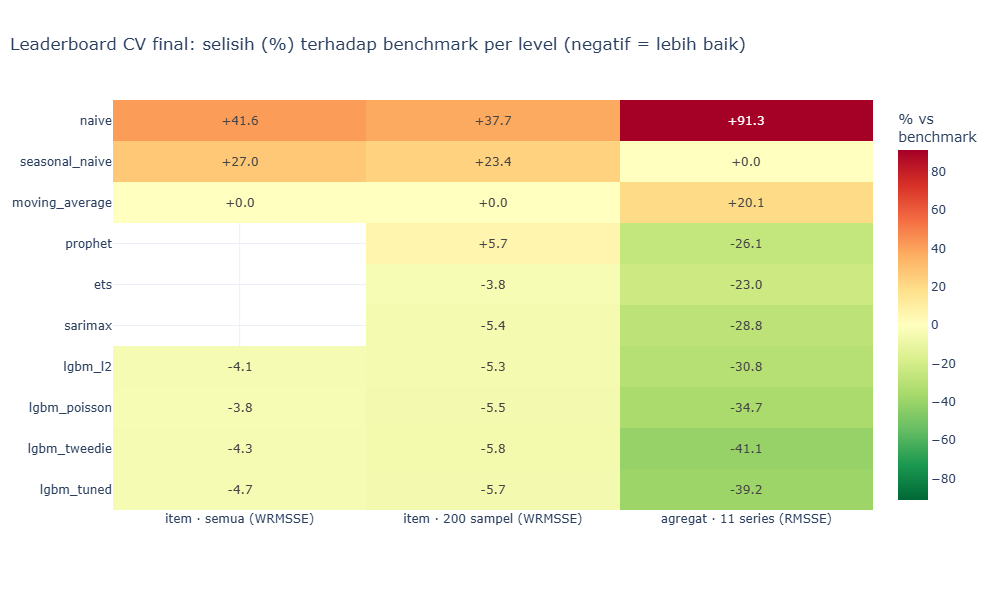

terbaik per level: {'item · semua (WRMSSE)': 'lgbm_tuned', 'item · 200 sampel (WRMSSE)': 'lgbm_tweedie', 'agregat · 11 series (RMSSE)': 'lgbm_tweedie'}


,item · semua (WRMSSE),item · 200 sampel (WRMSSE),agregat · 11 series (RMSSE)
model,,,
naive,1.1902,1.0572,1.7734
seasonal_naive,1.0681,0.9478,0.9270
moving_average,0.8407,0.7678,1.1128
prophet,NaN,0.8117,0.6851
ets,NaN,0.7383,0.7140
sarimax,NaN,0.7267,0.6599
lgbm_l2,0.8059,0.7273,0.6412
lgbm_poisson,0.8086,0.7253,0.6056
lgbm_tweedie,0.8045,0.7233,0.5462


In [2]:
views = {
    "item · semua (WRMSSE)": ("item", "all", "wrmsse", "moving_average"),
    "item · 200 sampel (WRMSSE)": ("item", "stat_sample", "wrmsse", "moving_average"),
    "agregat · 11 series (RMSSE)": ("agg", "all", "rmsse", "seasonal_naive"),
}
score, rel = {}, {}
for name, (level, subset, metric, bench) in views.items():
    b = board[(board["level"] == level) & (board["subset"] == subset)].set_index("model")
    score[name] = b[f"{metric}_mean"]
    rel[name] = 100 * (b[f"{metric}_mean"] / b.loc[bench, f"{metric}_mean"] - 1)
order = [
    "naive",
    "seasonal_naive",
    "moving_average",
    "prophet",
    "ets",
    "sarimax",
    "lgbm_l2",
    "lgbm_poisson",
    "lgbm_tweedie",
    "lgbm_tuned",
]
rel = pd.DataFrame(rel).reindex(order)
fig = plots.plot_heatmap(
    rel,
    fmt="+.1f",
    colorscale="RdYlGn_r",
    zmid=0,
    colorbar_title="% vs<br>benchmark",
    title="Leaderboard CV final: selisih (%) terhadap benchmark per level (negatif = lebih baik)",
)
fig.show()
plots.save_png(fig, "25_leaderboard_final_heatmap", config)
best = {name: s.reindex(order).idxmin() for name, s in score.items()}  # ablations excluded
print("terbaik per level:", best)
pd.DataFrame(score).reindex(order)

## 2 · Error per kelas demand × model

Kelas demand (Syntetos–Boylan, dihitung ≤ d_1801) mengelompokkan item berdasarkan seberapa sering terjual (ADI) dan seberapa bervariasi jumlahnya (CV²). Angka di heatmap adalah RMSSE rata-rata per item, tanpa bobot revenue, jadi setiap item dihitung sama.

**Insight:**
- **Smooth/erratic** (item yang laris dan rutin): LightGBM terbaik, lalu SARIMAX dan ETS. Seasonal Naive tertinggal jauh karena menyalin satu minggu lalu, sehingga ikut menyalin noise.
- **Intermittent** (72% item): semua model kecuali Seasonal Naive dan Prophet praktis sama (0,660–0,664). Untuk item yang hanya sesekali terjual 1–2 unit, tidak ada model yang bisa jauh lebih baik dari rata-rata 28 hari.
- **Lumpy** (jarang terjual, tapi sekali terjual jumlahnya besar): **ETS dan MA28 justru terbaik**, sedangkan LightGBM (0,671) kalah dari ETS, MA28, dan SARIMAX. Prophet (0,714) yang terburuk setelah Seasonal Naive. Dugaan (belum diuji): rata-rata yang halus lebih aman untuk lonjakan yang acak.
- Di semua item (tabel kedua), keunggulan LightGBM terhadap MA28 berkisar −4,5% (smooth) sampai −0,2% (lumpy). Penurunan WRMSSE LightGBM terhadap MA28 (0,841 → 0,801) kalau dipecah per kelas: smooth menyumbang ±42%, intermittent ±41%, lumpy ±10%, erratic ±7%. Smooth hanya 24% revenue, tetapi perbaikannya besar. Intermittent perbaikannya kecil per item, tetapi bobotnya 60% revenue.

**Implikasi:** tidak ada satu model yang menang di semua kelas. Kombinasi model per kelas (misalnya LightGBM untuk smooth/erratic dan ETS untuk lumpy) bisa jadi ide pengembangan, tapi tidak dicoba sekarang supaya pemilihan model tetap sederhana dan tidak *overfit* ke 4 fold.

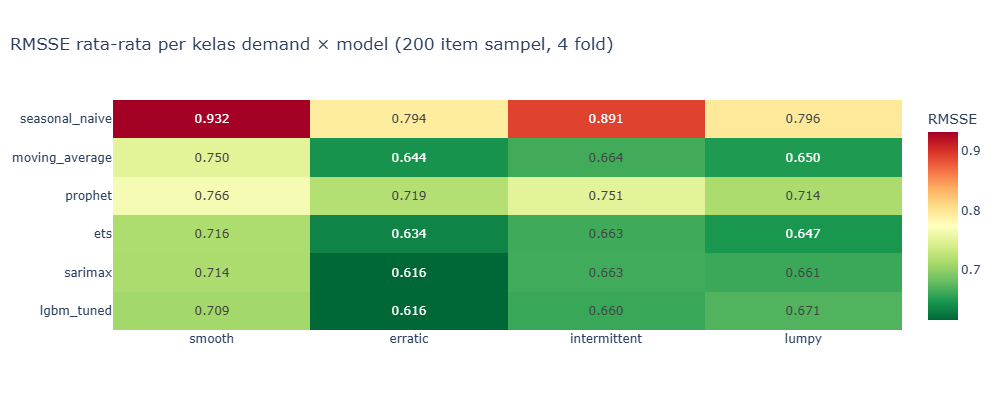

demand_class,smooth,erratic,intermittent,lumpy
model,,,,
seasonal_naive,0.9322,0.7936,0.8913,0.7959
moving_average,0.7501,0.6438,0.6635,0.6496
prophet,0.7657,0.7190,0.7506,0.7142
ets,0.7158,0.6342,0.6625,0.6466
sarimax,0.7143,0.6159,0.6633,0.6606
lgbm_tuned,0.7091,0.6156,0.6600,0.6708
terbaik,lgbm_tuned,lgbm_tuned,lgbm_tuned,ets


In [3]:
def rmsse_class(models: list[str], ids: set[str] | None) -> pd.DataFrame:
    data = items if ids is None else items[items["series_id"].astype(str).isin(ids)]
    rows = [per_series_rmsse(load_preds(m, ids=ids), data, folds).assign(model=m) for m in models]
    per = pd.concat(rows).merge(
        classes[["item_id", "demand_class"]], left_on="series_id", right_on="item_id"
    )
    per["demand_class"] = per["demand_class"].astype(str)
    per = per[per["demand_class"].isin(CLASS_ORDER)]
    return per.pivot_table(index="model", columns="demand_class", values="rmsse", aggfunc="mean")[
        CLASS_ORDER
    ]


cls_sample = rmsse_class(SAMPLE_MODELS, sample_ids).reindex(SAMPLE_MODELS)
fig = plots.plot_heatmap(
    cls_sample,
    colorscale="RdYlGn_r",
    colorbar_title="RMSSE",
    title="RMSSE rata-rata per kelas demand × model (200 item sampel, 4 fold)",
)
fig.show()
plots.save_png(fig, "26_rmsse_class_model_heatmap", config)
cls_sample.T.assign(terbaik=cls_sample.idxmin()).T

In [4]:
cls_all = rmsse_class(ALL_ITEM_MODELS, None).reindex(ALL_ITEM_MODELS)
share = classes["demand_class"].astype(str).value_counts().reindex(CLASS_ORDER)
print("jumlah item per kelas:", share.to_dict())
(100 * (cls_all / cls_all.loc["moving_average"] - 1)).round(1).rename_axis("% vs MA28 (semua item)")

jumlah item per kelas: {'smooth': 239, 'erratic': 83, 'intermittent': 2192, 'lumpy': 533}


demand_class,smooth,erratic,intermittent,lumpy
% vs MA28 (semua item),,,,
seasonal_naive,23.3000,24.2000,30.9000,27.8000
moving_average,0.0000,0.0000,0.0000,0.0000
lgbm_tweedie,-4.5000,-3.2000,-0.3000,0.0000
lgbm_tuned,-4.5000,-3.0000,-0.3000,-0.2000


## 3 · Error per hari horizon

Tabel dirangkum per minggu horizon (minggu 1 = h 1–7, …, minggu 4 = h 22–28).

**Insight, ini temuan terpenting notebook ini:**
- **Level item (tabel kedua):** error ETS dan SARIMAX **naik** dari minggu 1 ke minggu 4 (SARIMAX 0,595 → 0,648), sedangkan LightGBM hampir **datar** (0,615 → 0,631). Model statistik lebih baik di minggu pertama, LightGBM lebih baik di minggu keempat.
- **Dugaan penyebab (konsisten dengan data, tetapi belum diuji langsung):** model statistik melihat data sampai hari cutoff, sedangkan LightGBM (strategi direct, D-004) **hanya memakai data ≥ 28 hari sebelum hari yang diprediksi**, termasuk untuk h = 1. Untuk h = 1 berarti 27 hari terakhir tidak terpakai. Catatan: MA28 juga memakai data terbaru, tetapi tidak lebih baik dari LightGBM di minggu 1 (0,617 vs 0,615), jadi data terbaru saja bukan penjelasan lengkap.
- **Level agregat (grafik):** LightGBM bottom-up paling rendah di semua minggu. Error ETS/SARIMAX di minggu 1 justru paling tinggi di 3 dari 4 fold (di F3 yang tertinggi minggu 4). Penyebabnya belum diselidiki. Karena model final di agregat adalah LightGBM, hal ini tidak mengubah keputusan.

**Ide pengembangan (di luar scope):** model per-horizon. Misalnya model khusus minggu 1 yang boleh memakai lag ≥ 7, model minggu 2 dengan lag ≥ 14, dan seterusnya. Pendekatan ini berpotensi menggabungkan kelebihan kedua jenis model, tetapi belum dicoba di project ini.

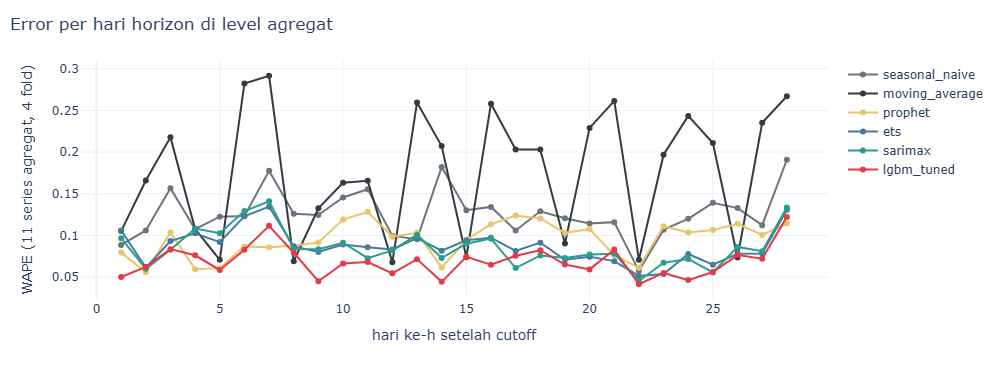

week,minggu 1,minggu 2,minggu 3,minggu 4
model,,,,
seasonal_naive,0.1260,0.1327,0.1215,0.1229
moving_average,0.1773,0.1521,0.1884,0.1854
prophet,0.0760,0.0986,0.1057,0.1016
ets,0.1019,0.0863,0.0828,0.0765
sarimax,0.1030,0.0839,0.0788,0.0774
lgbm_tuned,0.0751,0.0614,0.0722,0.0672


In [5]:
hz = pd.concat(
    [metrics_by_horizon(load_preds(m, "agg"), folds).assign(model=m) for m in AGG_MODELS]
)
fig = plots.plot_metric_by_horizon(
    hz,
    "wape",
    axis_title="WAPE (11 series agregat, 4 fold)",
    title="Error per hari horizon di level agregat",
)
fig.show()
plots.save_png(fig, "27_wape_by_horizon_agg", config)
hz["week"] = (hz["h"] - 1) // 7 + 1
hz.pivot_table(index="model", columns="week", values="wape").add_prefix("minggu ").reindex(
    AGG_MODELS
)

In [6]:
hz_s = pd.concat(
    [
        metrics_by_horizon(load_preds(m, ids=sample_ids), folds).assign(model=m)
        for m in SAMPLE_MODELS
    ]
)
hz_s["week"] = (hz_s["h"] - 1) // 7 + 1
hz_s.pivot_table(index="model", columns="week", values="wape").add_prefix("minggu ").reindex(
    SAMPLE_MODELS
)

week,minggu 1,minggu 2,minggu 3,minggu 4
model,,,,
seasonal_naive,0.7190,0.7716,0.7824,0.7959
moving_average,0.6166,0.6259,0.6574,0.6822
prophet,0.6504,0.6925,0.7116,0.7371
ets,0.5932,0.6241,0.6400,0.6580
sarimax,0.5945,0.6171,0.6297,0.6476
lgbm_tuned,0.6153,0.6200,0.6305,0.6312


## 4 · Error per departemen

RMSSE di sini adalah rata-rata per item, tanpa bobot revenue.

**Insight:**
- LightGBM lebih baik dari MA28 di 6 dari 7 departemen, tapi selisihnya kecil (−0,5% sampai −1,5%) kalau setiap item dihitung sama. Selisih −4,7% di WRMSSE muncul setelah pembobotan revenue, artinya LightGBM lebih unggul di item yang bobot revenue-nya besar di dalam tiap kelas.
- **HOUSEHOLD_2** adalah satu-satunya departemen tempat LightGBM sedikit kalah dari MA28 (+0,7%). Hampir semua itemnya (99,8%) intermittent/lumpy. Tetapi itu bukan penjelasan lengkap: HOBBIES_2 (100%) tetap sedikit lebih baik dengan LightGBM.
- **FOODS_3** (823 item, departemen terbesar) dan **HOUSEHOLD_1** mendapat perbaikan terbesar.

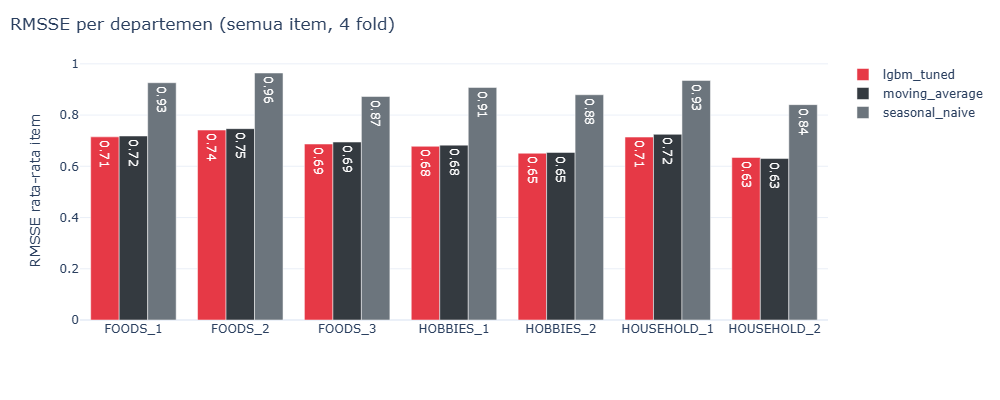

,seasonal_naive,moving_average,lgbm_tweedie,lgbm_tuned,lgbm vs MA28 (%),n_item
dept_id,,,,,,
FOODS_1,0.9263,0.7182,0.7144,0.7149,-0.4596,216
FOODS_2,0.9642,0.7469,0.7414,0.7415,-0.7244,398
FOODS_3,0.8725,0.6946,0.6881,0.6869,-1.1058,823
HOBBIES_1,0.9078,0.6826,0.6785,0.6781,-0.6685,416
HOBBIES_2,0.8794,0.6541,0.6516,0.6509,-0.4844,149
HOUSEHOLD_1,0.9350,0.7248,0.7140,0.7141,-1.4763,532
HOUSEHOLD_2,0.8407,0.6302,0.6352,0.6345,0.6708,515


In [7]:
dept_of = (
    items.drop_duplicates("series_id")
    .set_index(items.drop_duplicates("series_id")["series_id"].astype(str))["dept_id"]
    .astype(str)
)
rows = []
for m in ALL_ITEM_MODELS:
    r = per_series_rmsse(load_preds(m), items, folds)
    rows.append(r.assign(model=m, dept_id=r["series_id"].map(dept_of)))
dept = pd.concat(rows).groupby(["dept_id", "model"])["rmsse"].mean().reset_index()
fig = plots.plot_metric_by_group(
    dept[dept["model"] != "lgbm_tweedie"],
    "dept_id",
    "rmsse",
    axis_title="RMSSE rata-rata item",
    title="RMSSE per departemen (semua item, 4 fold)",
)
fig.show()
plots.save_png(fig, "28_rmsse_by_dept", config)
piv = dept.pivot(index="dept_id", columns="model", values="rmsse")[ALL_ITEM_MODELS]
piv["lgbm vs MA28 (%)"] = 100 * (piv["lgbm_tuned"] / piv["moving_average"] - 1)
piv.join(dept_of.value_counts().rename("n_item"))

## 5 · Hari event & SNAP

> **SNAP** adalah program bantuan pangan pemerintah AS. Di California, dana SNAP cair di 10 hari pertama setiap bulan, sehingga penjualan FOODS naik di hari-hari itu (EDA Q3).

**Catatan penting:** di 4 jendela validasi hanya ada **10 hari event** (dari 112 hari) dan 37 hari SNAP. Angka untuk hari event dihitung dari sampel kecil, jadi harus dibaca sebagai indikasi, bukan kesimpulan pasti.

**Insight:**
- **Hari event (total toko):** LightGBM paling akurat (WAPE 7,2%), disusul Prophet (7,6%), yang juga punya komponen holiday. ETS dan SARIMAX tanpa variabel event meleset ±11–12%, hampir dua kali error mereka di hari biasa.
- **SNAP:** model tanpa informasi SNAP (Seasonal Naive, ETS, SARIMAX) **under-forecast** 7–8% di hari SNAP. Prophet (regressor SNAP) dan LightGBM (fitur `snap`) jauh lebih kecil biasnya (−0,4% dan −2,2%). Fitur kalender yang "murah" ini terbukti berguna, konsisten dengan ablation di notebook 03.
- Di level item, perbedaan antar-model di hari event mengecil karena volumenya tersebar ke 3.049 item yang mayoritas intermittent.

di jendela validasi CV: {'non-event': 102, 'hari event': 10} {'non-SNAP': 75, 'SNAP': 37}
event: ['Easter', 'LentStart', 'LentWeek2', 'MartinLutherKingDay', 'OrthodoxChristmas', 'PresidentsDay', 'Purim End', 'StPatricksDay', 'SuperBowl', 'ValentinesDay']


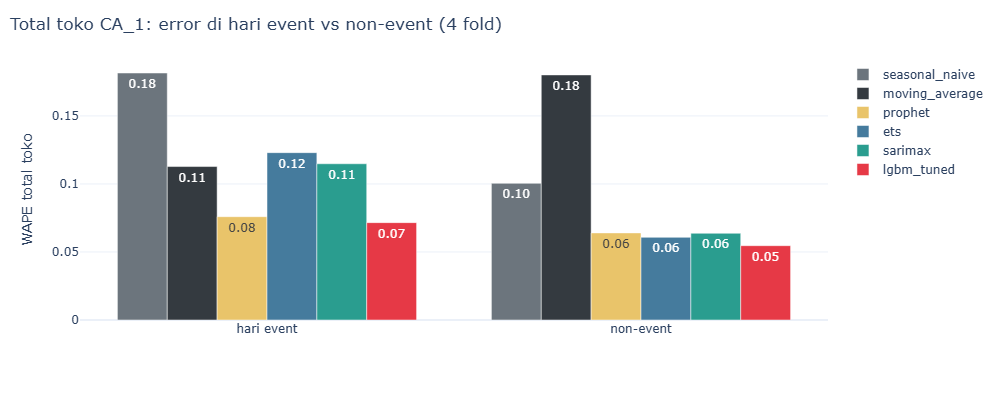

bias                                  wape            \
faktor              event              snap               event             
grup           hari event non-event    SNAP non-SNAP hari event non-event   
model                                                                       
seasonal_naive     0.0052   -0.0424 -0.0822  -0.0156     0.1815    0.1005   
moving_average     0.0019   -0.0255 -0.0525  -0.0079     0.1128    0.1801   
prophet           -0.0507   -0.0263 -0.0043  -0.0409     0.0759    0.0640   
ets               -0.0030   -0.0353 -0.0668  -0.0148     0.1230    0.0607   
sarimax           -0.0091   -0.0395 -0.0700  -0.0197     0.1148    0.0637   
lgbm_tuned        -0.0358   -0.0288 -0.0217  -0.0334     0.0716    0.0546   

                                
faktor           snap           
grup             SNAP non-SNAP  
model                           
seasonal_naive 0.1148   0.1036  
moving_average 0.1625   0.1805  
prophet        0.0540   0.0708  
ets            0.0797   0.0590  
sarimax        0.0837   0.0601  
lgbm_tuned     0.0600   0.0541

In [8]:
cal = items.drop_duplicates("d").set_index("d")
flags = pd.DataFrame(
    {
        "event": np.where(cal["event_name_1"].notna(), "hari event", "non-event"),
        "snap": np.where(cal["snap"] == 1, "SNAP", "non-SNAP"),
    },
    index=cal.index,
)
valid_days = pd.Index(np.concatenate([np.arange(f.valid_start, f.valid_end + 1) for f in folds]))
print(
    "di jendela validasi CV:",
    flags.loc[valid_days, "event"].value_counts().to_dict(),
    flags.loc[valid_days, "snap"].value_counts().to_dict(),
)
print(
    "event:",
    sorted(
        cal.loc[valid_days][cal.loc[valid_days, "event_name_1"].notna()]["event_name_1"].astype(str)
    ),
)

store = config["scope"]["store_id"]
ev_rows = []
for m in AGG_MODELS:
    p = load_preds(m, "agg")
    p = p[p["series_id"] == store].join(flags, on="d")
    for col in ["event", "snap"]:
        ev_rows.append(
            metrics_by_group(p, col).rename(columns={col: "grup"}).assign(model=m, faktor=col)
        )
ev = pd.concat(ev_rows)
fig = plots.plot_metric_by_group(
    ev[ev["faktor"] == "event"],
    "grup",
    "wape",
    axis_title="WAPE total toko",
    title="Total toko CA_1: error di hari event vs non-event (4 fold)",
)
fig.show()
plots.save_png(fig, "29_wape_event_vs_nonevent", config)
ev.pivot_table(index="model", columns=["faktor", "grup"], values=["wape", "bias"]).reindex(
    AGG_MODELS
)

In [9]:
# Same question at item level (all items), where volume is spread over 3,049 series.
it_rows = []
for m in ALL_ITEM_MODELS:
    p = load_preds(m).join(flags, on="d")
    for col in ["event", "snap"]:
        it_rows.append(
            metrics_by_group(p, col).rename(columns={col: "grup"}).assign(model=m, faktor=col)
        )
pd.concat(it_rows).pivot_table(
    index="model", columns=["faktor", "grup"], values=["wape", "bias"]
).reindex(ALL_ITEM_MODELS)

bias                                  wape            \
faktor              event              snap               event             
grup           hari event non-event    SNAP non-SNAP hari event non-event   
model                                                                       
seasonal_naive     0.0052   -0.0424 -0.0822  -0.0156     0.9251    0.8820   
moving_average     0.0020   -0.0254 -0.0524  -0.0078     0.7680    0.7582   
lgbm_tweedie      -0.0389   -0.0249 -0.0124  -0.0332     0.7668    0.7477   
lgbm_tuned        -0.0358   -0.0288 -0.0217  -0.0334     0.7617    0.7457   

                                
faktor           snap           
grup             SNAP non-SNAP  
model                           
seasonal_naive 0.8465   0.9060  
moving_average 0.7301   0.7740  
lgbm_tweedie   0.7426   0.7528  
lgbm_tuned     0.7420   0.7498

## 6 · Bias: over- atau under-forecast?

> **Bias** = Σ(prediksi − aktual) / Σ aktual. Nilai negatif berarti prediksi kurang dari aktual (*under-forecast*), yang di dunia nyata berarti risiko **stockout**. Nilai positif berarti stok menumpuk.

**Insight:**
- **Semua model sedikit under-forecast** secara total (−1% sampai −5%). Rata-rata penjualan harian naik dari fold ke fold (F1 4.218 → F4 4.570 unit), sehingga wajar kalau model yang belajar dari masa lalu tertinggal.
- **Item lumpy di-under-forecast oleh semua model** (−6% sampai −19%). LightGBM paling kecil biasnya di kelas ini (−6,2%).
- Bias LightGBM stabil antar-fold (−1,9% sampai −3,7%) dan tidak memburuk seiring waktu.
- Bias level item dan agregat untuk LightGBM, MA28, dan Seasonal Naive identik, karena jumlah prediksi item sama dengan prediksi agregat (bottom-up, dan MA/SN bersifat linear).

**Implikasi untuk Fase 7:** under-forecast yang sistematis, terutama di item lumpy, harus dikompensasi oleh **safety stock**. Interval prediksi dari residual backtest per kelas demand (D-006) akan otomatis menangkap bias ini, karena kuantil residual item lumpy akan condong ke atas.

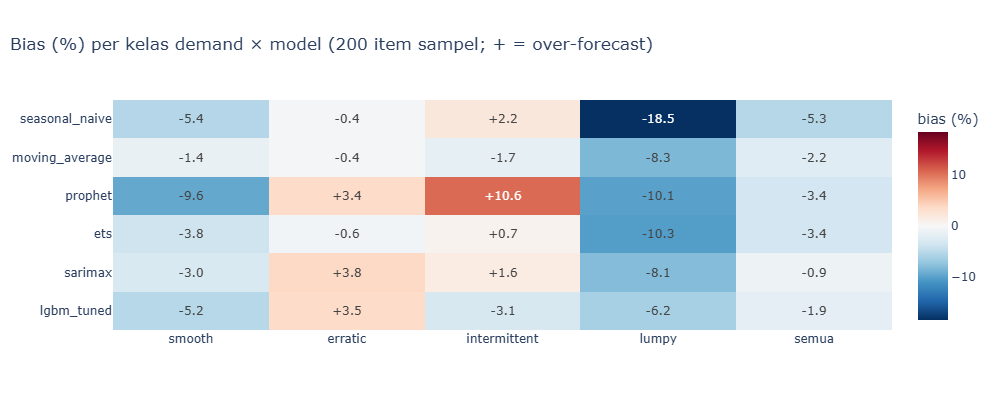

demand_class,smooth,erratic,intermittent,lumpy,semua
model,,,,,
seasonal_naive,-5.4046,-0.4111,2.1613,-18.5292,-5.3026
moving_average,-1.3628,-0.3620,-1.6605,-8.3496,-2.1986
prophet,-9.5561,3.4472,10.5598,-10.0990,-3.4403
ets,-3.7666,-0.6217,0.6981,-10.3462,-3.4270
sarimax,-2.9518,3.7905,1.5581,-8.0623,-0.9486
lgbm_tuned,-5.2279,3.5170,-3.1467,-6.1525,-1.8523


In [10]:
cls_map = (
    classes.assign(item_id=classes["item_id"].astype(str))
    .set_index("item_id")["demand_class"]
    .astype(str)
)
b_rows = []
for m in SAMPLE_MODELS:
    p = load_preds(m, ids=sample_ids)
    p["demand_class"] = p["series_id"].map(cls_map)
    b_rows.append(metrics_by_group(p, "demand_class").assign(model=m))
    b_rows.append(metrics_by_group(p.assign(demand_class="semua"), "demand_class").assign(model=m))
bias_tbl = (
    pd.concat(b_rows)
    .pivot(index="model", columns="demand_class", values="bias")[[*CLASS_ORDER, "semua"]]
    .reindex(SAMPLE_MODELS)
    * 100
)
fig = plots.plot_heatmap(
    bias_tbl,
    fmt="+.1f",
    colorscale="RdBu_r",
    zmid=0,
    colorbar_title="bias (%)",
    title="Bias (%) per kelas demand × model (200 item sampel; + = over-forecast)",
)
fig.show()
plots.save_png(fig, "30_bias_class_model_heatmap", config)
bias_tbl

In [11]:
# Bias per fold for the main candidates (all items / aggregate): is it stable over time?
mb = pd.read_csv(RESULTS / "metrics_by_fold.csv")
mb = mb[
    (mb["subset"] == "all")
    & mb["model"].isin(["seasonal_naive", "moving_average", "sarimax", "lgbm_tuned"])
]
(mb.pivot_table(index=["level", "model"], columns="fold", values="bias") * 100).round(1)

fold                      F1      F2      F3      F4
level model                                         
agg   lgbm_tuned     -3.7000 -3.6000 -1.9000 -2.7000
      moving_average -1.3000 -3.9000 -1.9000 -2.1000
      sarimax        -4.5000 -3.9000 -1.5000 -4.1000
      seasonal_naive -2.3000 -6.9000 -4.5000 -1.6000
item  lgbm_tuned     -3.7000 -3.6000 -1.9000 -2.7000
      moving_average -1.3000 -3.9000 -1.9000 -2.1000
      seasonal_naive -2.3000 -6.9000 -4.5000 -1.6000

## Ringkasan bagian A (CV)

1. **LightGBM global menang di level item secara keseluruhan** (WRMSSE 0,801, −4,7% vs MA28) dan **di level agregat** lewat bottom-up (RMSSE 0,55–0,56 vs SARIMAX 0,66). Keunggulan atas MA28 terutama datang dari item smooth dan intermittent (masing-masing ±41–42% dari penurunan WRMSSE). Ablation di notebook 03 menunjukkan fitur kalender sangat penting, terutama di agregat.
2. **Di 200 item sampel, LightGBM dan SARIMAX seri**, dan untuk item lumpy model sederhana (ETS, MA28) justru terbaik. Tidak ada model yang dominan di semua kelas demand.
3. **Pola horizon berbeda:** di level item (200 sampel), ETS/SARIMAX lebih akurat di minggu pertama, LightGBM lebih akurat di minggu keempat karena errornya hampir datar. Strategi direct (lag ≥ 28) adalah dugaan penyebabnya.
4. **Semua model under-forecast**, paling parah di item lumpy. Ini akan ditangani oleh safety stock di Fase 7.

**Model final dikunci:** `lgbm_tuned` (item + bottom-up agregat). Pembanding di test: SARIMAX (agregat + 200 sampel), MA28, dan Seasonal Naive.

---

## Bagian B · Hasil test set (d_1914–d_1941, 25 April – 22 Mei 2016)

Test set dievaluasi **satu kali** dengan `python -m scripts.final_test --confirm-final-test` (2026-11-23, tanpa re-run). Kandidat dan hyperparameter dikunci sebelumnya (D-025). Setiap model dilatih ulang di seluruh data ≤ d_1913, lalu memprediksi 28 hari yang belum pernah dilihat sama sekali selama pengembangan. Script menolak jalan untuk kedua kalinya.

Sebelum test dijalankan, fitur dibangun ulang dengan menyertakan jendela test, dan baris d ≤ 1913 terbukti **identik** dengan tabel fitur CV. Menambah data masa depan tidak mengubah satu pun fitur masa lalu.

**Insight:**
- **Metrik utama terkonfirmasi.** Di semua item, `lgbm_tuned` tetap terbaik: WRMSSE **0,798** (CV 0,801), **−4,3%** vs MA28 (0,833). Skor test hampir sama persis dengan CV, jadi backtest kita memberi estimasi yang jujur.
- **Agregat:** LightGBM bottom-up tetap nomor 1 (RMSSE 0,547 ≈ CV 0,564). Tapi SARIMAX membaik drastis (0,660 → 0,554), sehingga selisihnya tinggal ±1%. Seasonal Naive juga membaik 29%. Dugaan: pola mingguan bulan test lebih teratur, sehingga model berbasis pola mingguan diuntungkan (tetap ada event, misalnya Mother's Day dan Cinco de Mayo). Ini hanya satu periode, jadi tidak bisa dipastikan.
- **200 item sampel:** ranking LightGBM dan SARIMAX **bertukar** (SARIMAX 0,778 vs LightGBM 0,792). Selisihnya 1,8%, masih di dalam simpangan antar-fold di CV (±0,03), jadi konsisten dengan kesimpulan Bagian A bahwa keduanya seri di sampel ini. Skor SARIMAX, LightGBM, dan MA28 di sampel memburuk 7–9% dibanding CV (Seasonal Naive 1,5%). Penyebabnya belum diselidiki, tetapi sampel 200 item memang lebih *noisy* (std antar-fold 0,03 vs 0,01 di semua item).
- Ranking di level item semua dan agregat **tidak berubah sama sekali** dari CV ke test.

In [12]:
from forecasting.validation.backtest import get_test_fold

test = get_test_fold(config)
tres = pd.read_csv(RESULTS / "test_results.csv")
tres["skor"] = tres["wrmsse"].fillna(tres["rmsse"])
cv = board.assign(
    skor=board["wrmsse_mean"].fillna(board["rmsse_mean"]),
    std=board["wrmsse_std"].fillna(board["rmsse_std"]),
)
cmp = tres.merge(
    cv[["model", "level", "subset", "skor", "std"]],
    on=["model", "level", "subset"],
    suffixes=("_test", "_cv"),
)
cmp["Δ test vs CV (%)"] = 100 * (cmp["skor_test"] / cmp["skor_cv"] - 1)
cmp["rank CV"] = cmp.groupby(["level", "subset"])["skor_cv"].rank().astype(int)
cmp["rank test"] = cmp.groupby(["level", "subset"])["skor_test"].rank().astype(int)
cmp = cmp.sort_values(["level", "subset", "skor_test"])
cmp[
    [
        "level",
        "subset",
        "model",
        "skor_cv",
        "std",
        "skor_test",
        "Δ test vs CV (%)",
        "rank CV",
        "rank test",
        "wape",
        "bias",
    ]
].reset_index(drop=True)

,level,subset,model,skor_cv,std,skor_test,Δ test vs CV (%),rank CV,rank test,wape,bias
0,agg,all,lgbm_tuned,0.5638,0.0499,0.5472,-2.9382,1,1,0.0783,-0.0614
1,agg,all,sarimax,0.6599,0.0285,0.5540,-16.0423,2,2,0.0777,-0.0486
2,agg,all,seasonal_naive,0.9270,0.1241,0.6562,-29.2065,3,3,0.0859,-0.0556
3,agg,all,moving_average,1.1128,0.0896,1.0822,-2.7552,4,4,0.1613,-0.0453
4,item,all,lgbm_tuned,0.8010,0.0087,0.7978,-0.4044,1,1,0.7259,-0.0614
5,item,all,moving_average,0.8407,0.0115,0.8332,-0.8949,2,2,0.7478,-0.0453
6,item,all,seasonal_naive,1.0681,0.0209,1.0492,-1.7648,3,3,0.8680,-0.0556
7,item,stat_sample,sarimax,0.7267,0.0397,0.7776,7.0108,2,1,0.6292,-0.0677
8,item,stat_sample,lgbm_tuned,0.7242,0.0256,0.7917,9.3135,1,2,0.6516,-0.0286
9,item,stat_sample,moving_average,0.7678,0.0334,0.8279,7.8223,3,3,0.6598,-0.0332


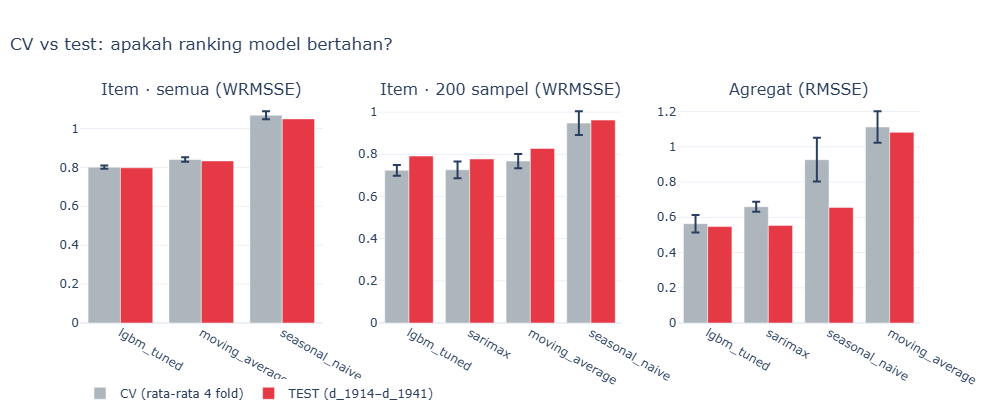

WindowsPath('C:/Projects/demand-forecasting-project/reports/figures/31_cv_vs_test.png')

In [13]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

panels = [
    ("item", "all", "Item · semua (WRMSSE)"),
    ("item", "stat_sample", "Item · 200 sampel (WRMSSE)"),
    ("agg", "all", "Agregat (RMSSE)"),
]
fig = make_subplots(rows=1, cols=3, subplot_titles=[t for *_, t in panels])
for i, (lvl, sub, _) in enumerate(panels, 1):
    c = cmp[(cmp["level"] == lvl) & (cmp["subset"] == sub)].sort_values("skor_cv")
    fig.add_trace(
        go.Bar(
            x=c["model"],
            y=c["skor_cv"],
            name="CV (rata-rata 4 fold)",
            marker_color="#adb5bd",
            error_y={"type": "data", "array": c["std"]},
            showlegend=i == 1,
        ),
        row=1,
        col=i,
    )
    fig.add_trace(
        go.Bar(
            x=c["model"],
            y=c["skor_test"],
            name="TEST (d_1914–d_1941)",
            marker_color="#e63946",
            showlegend=i == 1,
        ),
        row=1,
        col=i,
    )
fig.update_layout(
    template=plots.TEMPLATE,
    barmode="group",
    height=420,
    title="CV vs test: apakah ranking model bertahan?",
    title_x=0.01,
    legend={"orientation": "h", "y": -0.25},
)
fig.show()
plots.save_png(fig, "31_cv_vs_test", config)

**Bias membesar di test.** Semua model under-forecast lebih banyak dibanding di CV: LightGBM −6,1% (CV ±−3%), SARIMAX −4,9%, MA28 −4,5%. Grafik di bawah memperlihatkan hal yang sama: penjualan aktual hampir selalu di atas prediksi, terutama di hari kerja dan puncak 15 Mei. Penjualan toko naik 4,7% dari F4 (4.570 unit/hari) ke test (4.787), lebih besar dari kenaikan antar-fold sebelumnya (±2–4%). Di semua item, bias LightGBM (−6,1%) paling besar; tetapi di 200 sampel justru SARIMAX (−6,8%) dan Seasonal Naive (−9,1%) yang lebih parah (LightGBM −2,9%). Dugaan bahwa lag ≥ 28 memperbesar bias LightGBM belum diuji.

Ini temuan penting untuk Fase 7: safety stock harus cukup untuk menutup under-forecast seperti ini, dan simulasi inventori di periode test akan menguji apakah interval dari residual CV masih cukup.

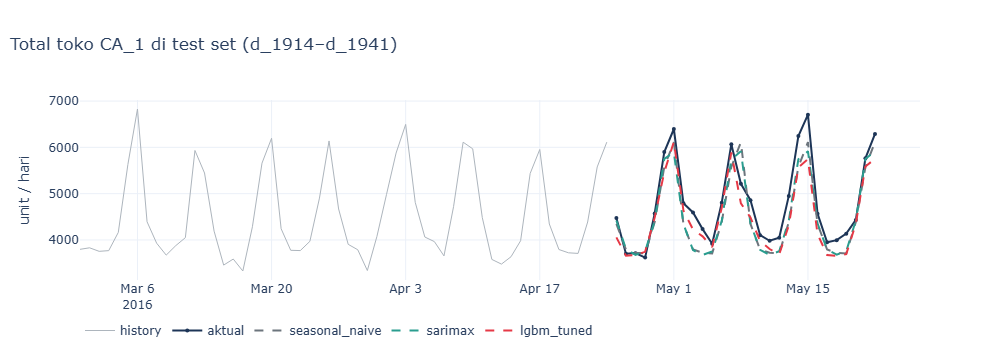

WindowsPath('C:/Projects/demand-forecasting-project/reports/figures/32_forecast_store_test.png')

In [14]:
agg_t = load_level_data(config, "agg", include_test=True)
store_t = agg_t[agg_t["series_id"] == config["scope"]["store_id"]]
hist = store_t[store_t["d"].between(test.train_end - 55, test.train_end)][["date", "sales"]]
actual = store_t[store_t["d"].between(test.valid_start, test.valid_end)][["date", "sales"]]
actual = actual.rename(columns={"sales": "y_true"})
parts = []
for m in ["seasonal_naive", "sarimax", "lgbm_tuned"]:
    p = pd.read_parquet(PREDS / f"test_{m}_agg.parquet")
    p = p[p["series_id"].astype(str) == config["scope"]["store_id"]]
    parts.append(p.merge(store_t[["d", "date"]], on="d")[["date", "y_pred"]].assign(model=m))
fig = plots.plot_forecast_vs_actual(
    hist, actual, pd.concat(parts), title="Total toko CA_1 di test set (d_1914–d_1941)"
)
fig.show()
plots.save_png(fig, "32_forecast_store_test", config)

In [15]:
items_t = load_level_data(config, "item", include_test=True)
rows = []
for m, ids in [
    ("seasonal_naive", None),
    ("moving_average", None),
    ("lgbm_tuned", None),
    ("sarimax", sample_ids),
]:
    p = pd.read_parquet(PREDS / f"test_{m}_item.parquet")
    p["series_id"] = p["series_id"].astype(str)
    data = items_t if ids is None else items_t[items_t["series_id"].astype(str).isin(ids)]
    for subset, sub_ids in [("semua", None), ("200 sampel", sample_ids)]:
        if ids is not None and subset == "semua":
            continue
        q = p if sub_ids is None else p[p["series_id"].isin(sub_ids)]
        r = per_series_rmsse(q, data, [test]).merge(
            classes[["item_id", "demand_class"]], left_on="series_id", right_on="item_id"
        )
        rows.append(r.assign(model=m, subset=subset))
tc = pd.concat(rows)
tc["demand_class"] = tc["demand_class"].astype(str)
tc = tc[tc["demand_class"].isin(CLASS_ORDER)]
tc.pivot_table(index=["subset", "model"], columns="demand_class", values="rmsse", aggfunc="mean")[
    CLASS_ORDER
]

demand_class               smooth  erratic  intermittent  lumpy
subset     model                                               
200 sampel lgbm_tuned      0.7756   0.6902        0.8084 0.7268
           moving_average  0.8200   0.6830        0.8254 0.7284
           sarimax         0.7599   0.6592        0.8103 0.7115
           seasonal_naive  0.9525   0.8151        1.0478 0.8852
semua      lgbm_tuned      0.7236   0.6793        0.7582 0.7316
           moving_average  0.7736   0.6851        0.7722 0.7385
           seasonal_naive  0.9248   0.8164        1.0031 0.9434

Tabel di atas: RMSSE per kelas demand di test. Di semua item, LightGBM lebih baik dari MA28 di **keempat kelas** (smooth −6,5%, intermittent −1,8%, lumpy −0,9%, erratic −0,8%). Di 200 sampel, SARIMAX unggul di smooth, erratic, dan lumpy. Seperti di CV, keunggulan terbesar LightGBM atas MA28 ada di item smooth.

## Ringkasan akhir Fase 6

1. **LightGBM global adalah model final.** Di metrik utama (WRMSSE semua item), LightGBM menang di CV (0,801) maupun test (0,798), sekitar 4,3–4,7% lebih baik dari MA28. Skor test yang hampir identik dengan CV menunjukkan bahwa backtest 4 fold memberi estimasi yang realistis untuk metrik ini (dengan catatan: test hanya satu periode).
2. **Di level agregat, LightGBM bottom-up juga nomor 1**, tapi keunggulannya atas SARIMAX menyempit dari ±15% di CV menjadi ±1% di test. Kelebihan bottom-up tetap ada: satu model menghasilkan forecast yang konsisten di semua level.
3. **Di 200 item sampel, LightGBM dan SARIMAX seri** (bergantian menang di CV dan test, selisih masih di dalam simpangan antar-fold). SARIMAX tidak dijalankan di semua item, jadi keduanya tidak dibandingkan di skala penuh.
4. **Yang terbukti membantu LightGBM:** fitur kalender (ablation notebook 03). **Kelemahan yang terukur:** kalah dari ETS/SARIMAX di minggu pertama (200 sampel), kalah di item lumpy sampel, dan bias −6,1% di test. Dugaan penyebab (lag ≥ 28 tidak memakai data terbaru) belum diuji.
5. **Semua model under-forecast**, dan di test lebih parah (−4,5% sampai −6,1% di semua item; −2,9% sampai −9,1% di 200 sampel). Ini masukan langsung untuk safety stock di Fase 7.